[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kvoytova-cyber/museumcanon/blob/main/demo.ipynb)

# museumcanon: русское и советское искусство в MoMA и Tate

**Что делает инструмент.** Берёт открытые данные любого музея и показывает, как в его коллекции и выставках представлена выбранная группа художников: кто, сколько, когда поступало, как (дар или покупка), с кем выставлялось.

- **На входе:** файлы музея (csv / xlsx / json) + YAML-маппинг «какое поле в какой колонке» + YAML с группами художников.
- **На выходе:** сводная таблица, графики поступлений и выставок, сеть совместных выставок, таблицы дарителей и «посредников».

Ноутбук показывает три блока пакета на демо-кейсе (Россия, бывшая империя/СССР, Восточная Европа в MoMA и Tate), а в конце — что тот же код без изменений работает с другой группой и с файлом в другом формате.

## Запуск

**Google Colab:** Runtime → Run all. Первая ячейка клонирует репозиторий и ставит зависимости — остальной ноутбук не отличается от локального запуска.

**Локально:** запускать из корня проекта (там, где лежит этот файл) после `pip install -r requirements.txt`.

In [1]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/kvoytova-cyber/museumcanon.git"
REPO_DIR = "museumcanon"

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if not os.path.exists(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    print(f"Colab: репозиторий в {os.getcwd()}, зависимости установлены.")
else:
    print(f"Локальный запуск из {os.getcwd()}.")

Локальный запуск из /Users/ksenia/Documents/museumcanon_project.


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

import museumcanon as mc

pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110

## 0. Данные

Ссылки лежат в конфигах (`url` у каждой таблицы). Уже скачанное повторно не качается. Коллекция MoMA хранится в Git LFS: если не скачается, положите `Artists.csv` и `Artworks.csv` в `data/raw/` как `moma_artists.csv` и `moma_artworks.csv` вручную — ноутбук продолжит работать и без них, на выставках MoMA и Tate.

In [3]:
mc.download(["configs/moma.yaml", "configs/tate.yaml"])

уже есть  data/raw/moma_artists.csv (1.1 МБ)
уже есть  data/raw/moma_artworks.csv (73.4 МБ)
уже есть  data/raw/moma_exhibitions.csv (10.8 МБ)
уже есть  data/raw/tate_artists.csv (0.5 МБ)
уже есть  data/raw/tate_artworks.csv (24.4 МБ)


## 1. Чтение: файл → объекты

`load_collection` читает конфиг, выбирает ридер по расширению (`CsvReader`, `ExcelReader`, `JsonReader` — наследники `TableReader`) и превращает строки в `Artist`, `Artwork`, `Exhibition`, собранные в `Collection`.

In [4]:
moma = mc.load_collection("configs/moma.yaml", skip_missing=True)
tate = mc.load_collection("configs/tate.yaml", skip_missing=True)
moma, tate

(Collection('MoMA': 21100 художников, 160928 работ, 1506 выставок),
 Collection('Tate': 3532 художников, 69201 работ, 0 выставок))

In [5]:
gabo_moma = moma.find("Naum Gabo")[0]
gabo_tate = tate.find("Gabo")[0]
print(gabo_moma, "|", gabo_moma.artist_id, gabo_moma.nationality, gabo_moma.birth_country)
print(gabo_tate, "|", gabo_tate.artist_id, gabo_tate.birth_place, gabo_tate.birth_country)

# Artist.__eq__ / __hash__: один человек в двух музеях
print("один и тот же художник:", gabo_moma == gabo_tate)

Naum Gabo (1890–1977) | MoMA:2043 American Russia
Gabo, Naum (1890–1977) | Tate:1137 Klimovichi Belarus
один и тот же художник: True


In [6]:
# Collection.__add__: два музея -> одна коллекция с общей моделью данных
both = moma + tate
print(both)
print("работ (Collection.__len__):", len(both))
print("Габо есть в объединённой коллекции (__contains__):", gabo_tate in both)
print("художников без дублей между музеями:", len(both.unique_artists()), "из", len(both.artists))

# Artwork.__lt__: сортировка по году поступления
first = sorted(both.artworks_by(gabo_tate))[:3]
[(w.title, w.acquisition_year, w.acquisition_type) for w in first]

Collection('MoMA + Tate': 24632 художников, 230129 работ, 1506 выставок)
работ (Collection.__len__): 230129
Габо есть в объединённой коллекции (__contains__): True
художников без дублей между музеями: 23455 из 24632


[('Spiral Theme', 1958, 'дар'),
 ('Linear Construction No. 1', 1958, 'дар'),
 ('Bronze Spheric Theme', 1966, 'покупка')]

## 2. Предобработка и отбор

`Cleaner` применяет секцию `cleaning` из конфига музея: нормализует страны (`Rossiya` → `Russia`), вносит ручные поправки, убирает безымянных «производителей» и исключает ложные срабатывания. Каждый шаг помечен декоратором `@step` и печатает, сколько записей он изменил.

In [7]:
moma = mc.Cleaner.from_config("configs/moma.yaml").run(moma)
tate = mc.Cleaner.from_config("configs/tate.yaml").run(tate)
both = moma + tate

Очистка MoMA:
  drop_by_pattern        художников  21100 → 21043  работ  160928 → 156589
Очистка Tate:
  drop_named             художников   3532 → 3531   работ   69201 → 29812


Группы задаются в `configs/groups_russia.yaml`: страны рождения и национальности. Художник попадает в первую подходящую группу. **Эмигрант** — родился в стране группы, но музей записал другую национальность (Кандинский в MoMA: `French, born Russia`). В Tate национальностей нет, поэтому там эмигрантов определить нельзя.

In [8]:
grouping = mc.Grouping.from_yaml("configs/groups_russia.yaml")
russia, ex_ussr, east = grouping.selectors

kandinsky = moma.find("Kandinsky")[0]
print(kandinsky, kandinsky.nationality, kandinsky.birth_country)
print("в группе «Россия» (Selector.__contains__):", kandinsky in russia, "| эмигрант:", russia.is_emigre(kandinsky))

# Selector.__or__: объединить группы в одно правило
wide = russia | ex_ussr
chagall = moma.find("Marc Chagall")[0]
print(chagall, chagall.birth_country, "| в «Россия»:", chagall in russia, "| в «Россия + бывш. СССР»:", chagall in wide)

Vasily Kandinsky (1866–1944) French Russia
в группе «Россия» (Selector.__contains__): True | эмигрант: True
Marc Chagall (1887–1985) Belarus | в «Россия»: False | в «Россия + бывш. СССР»: True


## 3. Визуализация

In [9]:
viz = mc.Visualizer(both, grouping, start=1920, bin_size=10, out_dir="output")
viz.summary()

,музей,группа,художников,из них эмигрантов,работ,выставок
0,MoMA,Россия,331,55,3693,302
1,MoMA,бывш. империя/СССР,70,35,3450,298
2,MoMA,Восточная Европа,525,110,5109,391
3,Tate,Россия,28,0,101,0
4,Tate,бывш. империя/СССР,31,0,327,0
5,Tate,Восточная Европа,108,0,332,0


### Поступления по десятилетиям

Штриховка выделяет работы одного дарителя (параметр `highlight` — регулярное выражение по credit line). Для MoMA это дар Judith Rothschild Foundation 2001 года: без выделения он выглядит как «пик интереса к русскому искусству в 2000-е».

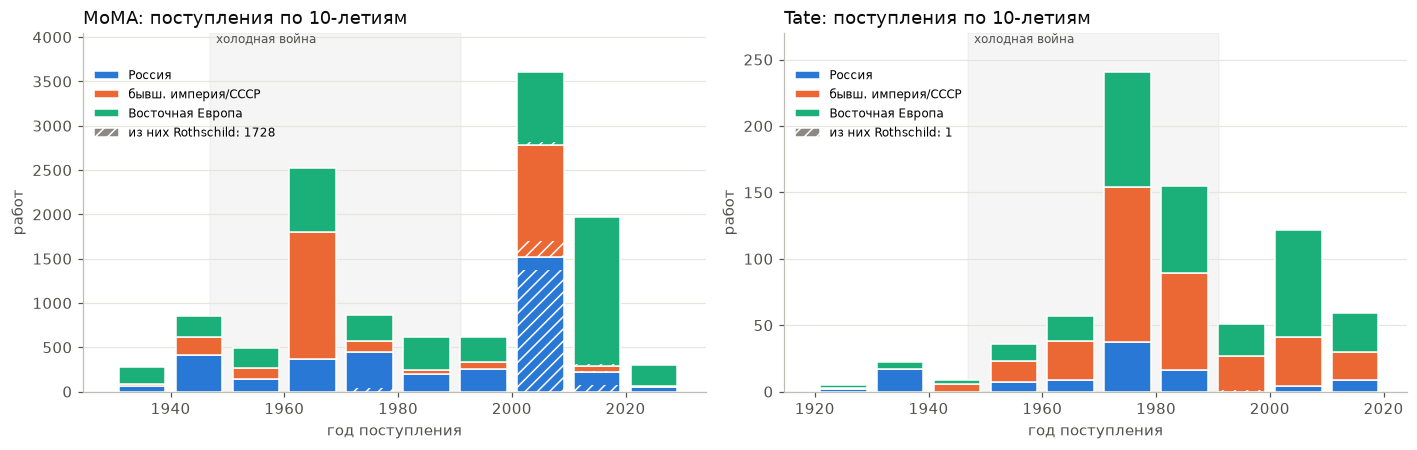

In [10]:
viz.plot_acquisitions(highlight="Rothschild");

group,Россия,бывш. империя/СССР,Восточная Европа
period,,,
1930,3.46,1.25,10.94
1940,5.65,2.76,3.28
1950,2.25,1.89,3.53
1960,0.83,3.21,1.61
1970,3.40,0.92,2.26
1980,1.98,0.44,3.76
1990,2.20,0.67,2.52
2000,6.26,5.16,3.41
2010,0.95,0.28,7.17


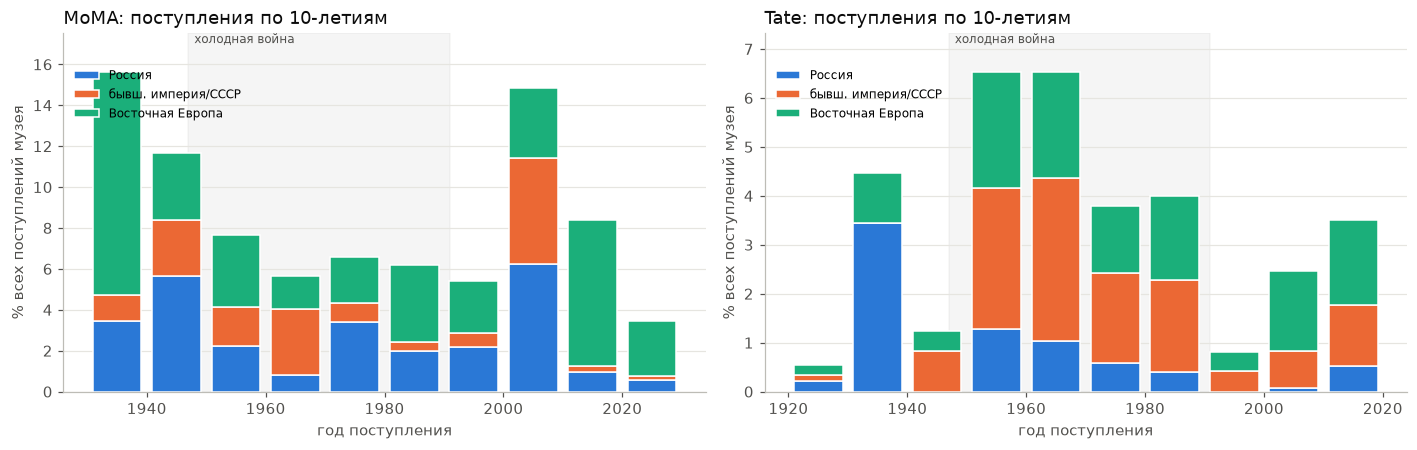

In [11]:
# доля от всех поступлений музея за период: так можно сравнивать музеи разного масштаба
viz.plot_acquisitions(share=True);
viz.acquisitions("MoMA", share=True)

### Кто сформировал корпус: дары и покупки, крупнейшие дарители

,museum,credit_line,работ,с,по,"доля, %"
0,MoMA,Gift of The Judith Rothschild Foundation,1128,2001.0,2003.0,30.5
1,MoMA,Gift of the artist,219,1932.0,2016.0,5.9
2,MoMA,Gift of Abby Aldrich Rockefeller,153,1935.0,1940.0,4.1
3,MoMA,Purchase,152,1935.0,2016.0,4.1
4,MoMA,Gift of The Judith Rothschild Foundation (Bori...,137,2001.0,2001.0,3.7
5,MoMA,Gift of Eric Estorick in memory of Judge Henry...,124,1962.0,1962.0,3.4
6,MoMA,The Louis E. Stern Collection,105,1964.0,1964.0,2.8
7,MoMA,The Merrill C. Berman Collection. Acquired thr...,74,2018.0,2018.0,2.0
8,MoMA,Committee on Architecture and Design Funds,59,2015.0,2018.0,1.6
9,MoMA,Larry Aldrich Fund,59,1953.0,1977.0,1.6


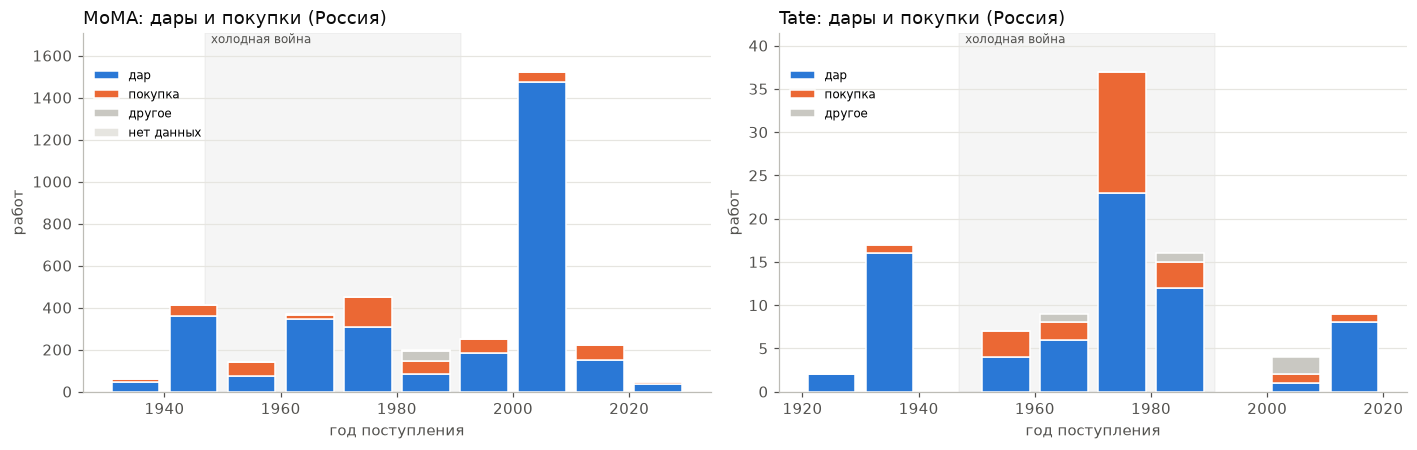

In [12]:
viz.plot_acquisition_types(group="Россия");
viz.top_donors("MoMA", "Россия", n=10)

### Выставки MoMA 1929–1989

,exhibition_id,title,start_year,художников группы
0,MoMA:1407,"Contrasts of Form: Geometric Abstract Art, 191...",1985,24
1,MoMA:1232,"Revolution: Russian Avant-Garde, 1912–1930",1978,23
2,MoMA:1277,Art of the Twenties,1979,19
3,MoMA:46,Cubism and Abstract Art,1936,18
4,MoMA:567,XXVth Anniversary Exhibition: Paintings from t...,1954,15
5,MoMA:1524a,Painters for the Theater,1989,11
6,MoMA:47,Modern Painters and Sculptors as Illustrators,1936,11
7,MoMA:33a,International Exhibition of Theatre Art,1934,11
8,MoMA:290,The Museum Collection of Painting and Sculpture,1945,10
9,MoMA:974,Ways of Looking,1971,10


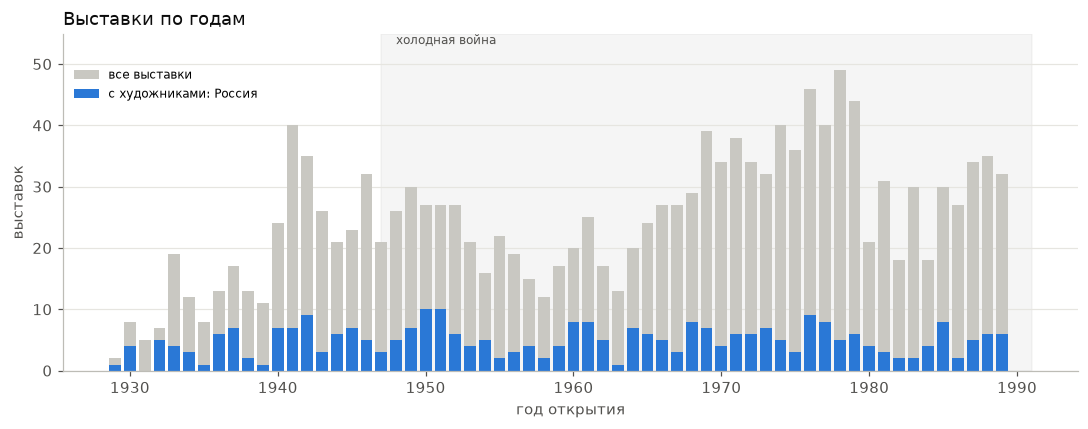

In [13]:
viz.plot_exhibitions("Россия");
viz.top_exhibitions("Россия", n=10)

### Сеть совместных выставок

Узлы — художники группы, ребро — не меньше `min_shared` общих выставок. Таблица «посредничества» (betweenness) показывает, через кого связана сеть. Интерактивная версия со всеми группами сохраняется в `output/network.html`.

,художник,группа,эмигрант,выставок,связей,посредничество
0,Pavel Tchelitchew,Россия,True,59,34,0.179
1,Alexander Liberman,Россия,True,20,6,0.139
2,Vasily Kandinsky,Россия,True,81,37,0.112
3,El Lissitzky,Россия,False,44,39,0.107
4,Roman Vishniac,Россия,True,9,4,0.059
5,Aleksandr Rodchenko,Россия,False,24,34,0.058
6,Kazimir Malevich,Россия,False,34,34,0.053
7,Naum Gabo,Россия,True,28,25,0.053
8,Mikhail Larionov,Россия,False,20,31,0.049
9,Vasily Yakovlovich Sitnikov,Россия,False,5,3,0.030


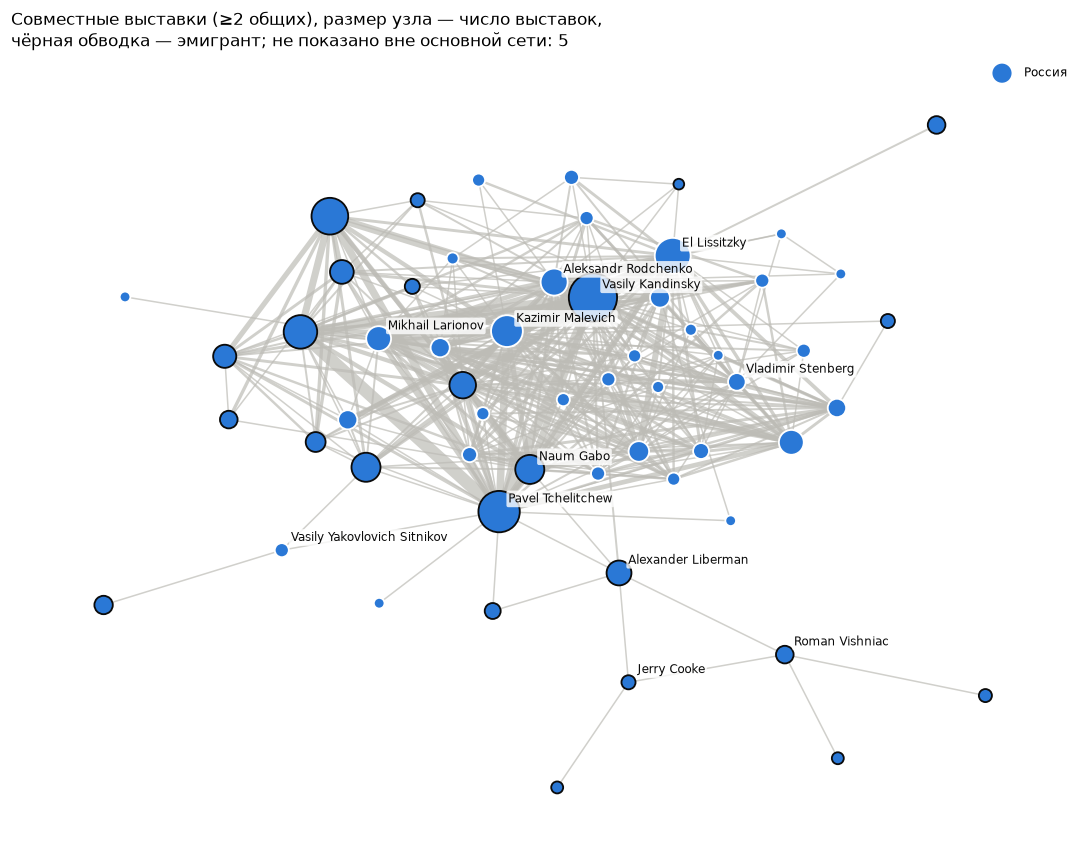

In [14]:
viz.plot_network(["Россия"], min_shared=2);
viz.centrality(viz.co_exhibition_graph(["Россия"], min_shared=2), n=12)

In [15]:
viz.plot_network(grouping.names, min_shared=2, html="network.html")

PosixPath('output/network.html')

In [16]:
from IPython.display import HTML

# HTML(filename=...) встраивает содержимое файла прямо в ячейку вывода.
# IFrame(src="путь к локальному файлу") в Colab часто не работает: песочница вывода
# не видит локальную файловую систему по относительному пути так, как это делает Jupyter.
HTML(filename="output/network.html")

### Те же графики с другими параметрами

Все методы принимают параметры, а настройки визуализатора можно поменять и перестроить график.

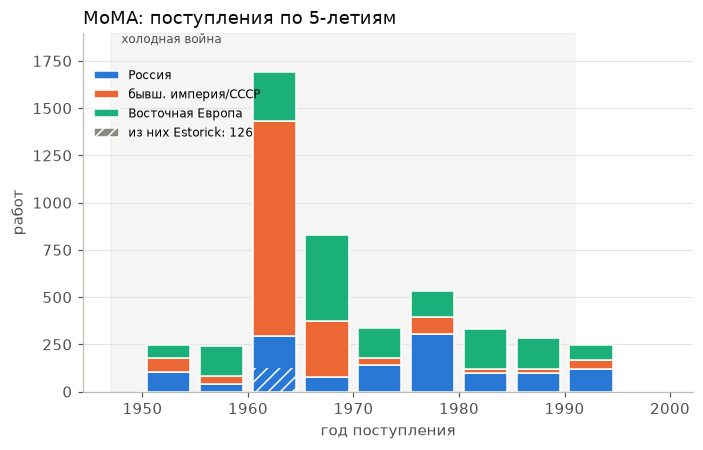

In [17]:
fine = mc.Visualizer(both, grouping, start=1950, end=1995, bin_size=5)
fine.plot_acquisitions(museums=["MoMA"], highlight="Estorick");

## 4. Другой вопрос — тот же код

Меняем только YAML с группами: японские художники в тех же музеях.

,музей,группа,художников,из них эмигрантов,работ,выставок
0,MoMA,Япония,565,15,3319,149
1,Tate,Япония,27,0,171,0


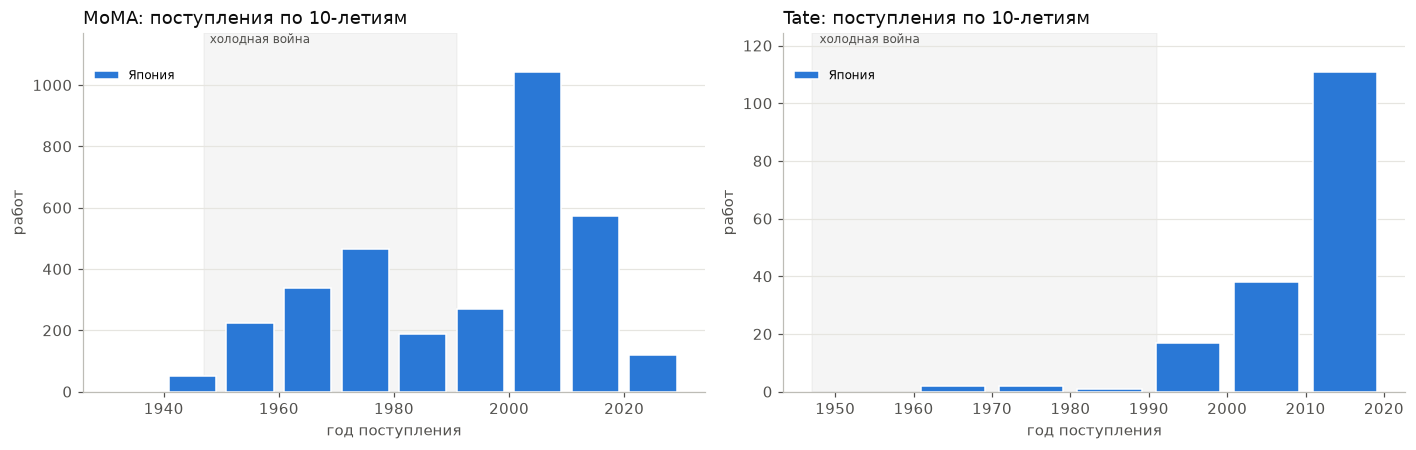

In [18]:
japan = mc.Visualizer(both, mc.Grouping.from_yaml("configs/groups_japan.yaml"))
display(japan.summary())
japan.plot_acquisitions();

## 5. Другой формат — тот же код

`examples/excel_example.xlsx` — Excel с двумя листами и русскими названиями колонок, годы жизни одной строкой. Всё, что нужно, — маппинг в `examples/excel_example.yaml`. Если колонка указана неверно, загрузчик подскажет похожие названия.

In [19]:
excel = mc.load_collection("examples/excel_example.yaml")
excel = mc.Cleaner.from_config("examples/excel_example.yaml").run(excel)
mc.Visualizer(excel, grouping).summary()

Очистка Пример (Excel):


,музей,группа,художников,из них эмигрантов,работ,выставок
0,Пример (Excel),Россия,11,0,36,0
1,Пример (Excel),бывш. империя/СССР,3,0,4,0
2,Пример (Excel),Восточная Европа,14,0,91,0


In [20]:
try:
    mc.load_collection({"name": "тест", "tables": {"artists": {
        "path": "examples/excel_example.xlsx", "read_options": {"sheet_name": "Авторы"},
        "fields": {"artist_id": "инв код автора", "name": "Автор"}}}})
except mc.ConfigError as error:
    print(error)

[artists] поле 'artist_id': колонки 'инв код автора' нет в файле. Похожие: Инв. код автора. Все колонки: Инв. код автора, Автор, Годы жизни, Место рождения


## Ограничения

- Группа определяется по записи музея: национальность и место рождения могут быть неполными или спорными (украинцы, эмигранты, «Russia» в границах империи). Спорные случаи правятся в секции `cleaning` конфига.
- Художники сопоставляются между музеями по имени и году рождения: «Natalia» и «Natalya» Гончарова не совпадут.
- Данные Tate — срез на 2014 год (с тех пор не обновлялись), выставки MoMA — только 1929–1989.
- Год рождения и год создания извлекаются из строк по первому найденному году: для «c. 1915–20» это 1915.